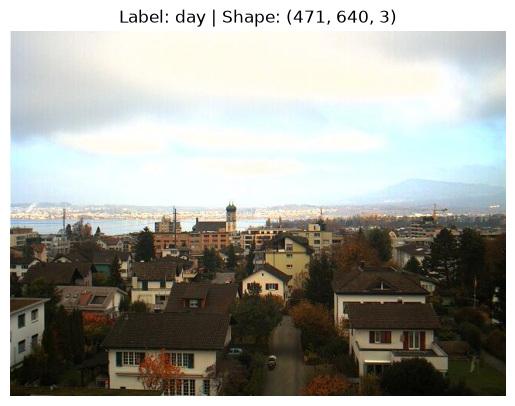

--- Threshold Evaluation ---
Accuracy (Threshold 120): 0.8417
Accuracy (Threshold 120): 0.8688

--- SVM Model Evaluation ---
Accuracy on train: 0.8583
Accuracy on test : 0.9000


In [1]:
# ==============================================================================
# LAB: Day and Night Image Classification using Threshold & SVM
# ==============================================================================

# --- Step 0: Import Libraries & Path Setup ---
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Tentukan direktori dataset
train_dir = "images/training/"
test_dir = "images/test/"


# --- Step 1: Load Data and Visualization Function ---
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []
    for d in dirs:
        # Mengambil nama folder sebagai label ('day' atau 'night')
        label = d.name 
        for file in d.glob('*.jpg'):
            img = mpimg.imread(file)
            if img is not None:
                img_list.append((img, label))
    return img_list

# Load training data
train_img = load_dataset(train_dir)

# Fungsi Visualisasi Acak
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img, label = img_list[rand_num]
    plt.imshow(img)
    plt.title(f"Label: {label} | Shape: {img.shape}")
    plt.axis('off')
    plt.show()

# Cek visualisasi acak data awal
if len(train_img) > 0:
    random_img_viz(train_img)


# --- Step 3: Data Preprocessing ---
def standarized_input(image):
    # Resize gambar ke w: 1100, h: 600
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    # Encode label: 'day' -> 1, 'night' -> 0
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []
    for image, label in img_list:
        std_img = standarized_input(image)
        img_label = label_encoder(label)
        std_img_list.append((std_img, img_label))
    return std_img_list

# Jalankan Preprocessing pada Data Training
train_std_img_list = preprocess(train_img)


# --- Step 4: Feature Extraction (Average Brightness HSV) ---
def avg_brightness(image):
    # Konversi RGB ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    # Hitung rata-rata channel V (Value/Brightness)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    return sum_brightness / area


# --- Step 5 & 6: Classification & Manual Evaluation (Threshold Method) ---
def predict_label(img, threshold=120):
    avg = avg_brightness(img)
    return 1 if avg > threshold else 0

def evaluate(img_list, threshold=120):
    miss_labels = []
    for img, label in img_list:
        pred_label = predict_label(img, threshold)
        if pred_label != label:
            miss_labels.append((img, pred_label, label))
    
    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img if total_img > 0 else 0
    print(f'Accuracy (Threshold {threshold}): {accuracy:.4f}')
    return accuracy

# Evaluasi metode Threshold pada Training Data
print("--- Threshold Evaluation ---")
evaluate(train_std_img_list, threshold=120)

# Load dan Preprocess Test Data
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)

# Evaluasi metode Threshold pada Test Data
evaluate(test_std_img_list, threshold=120)


# --- Alternative Method: Classification with SVM ---

# Alternative Step 4: Feature Vector Tabulation
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []
    for img, label in img_list:
        avg_list.append(avg_brightness(img))
        labels.append(label)
    
    data = np.column_stack((avg_list, labels))
    return pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

# Buat DataFrame fitur untuk Train dan Test
train_avg_df = extract_avg_bright_feature(train_std_img_list)
test_avg_df = extract_avg_bright_feature(test_std_img_list)

# Split Feature (X) dan Target (y)
X_train = train_avg_df[['AVG_BRIGHT']].values
y_train = train_avg_df['LABELS'].values

X_test = test_avg_df[['AVG_BRIGHT']].values
y_test = test_avg_df['LABELS'].values

# Step 5: Build & Train SVM Model
model = SVC(kernel='rbf')
model.fit(X_train, y_train)

# Step 6: Evaluation Model SVM
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test, y_test_pred)

print("\n--- SVM Model Evaluation ---")
print(f'Accuracy on train: {acc_train:.4f}')
print(f'Accuracy on test : {acc_test:.4f}')